<a href="https://colab.research.google.com/github/Hareeshgovindu/Research-Community-Detection/blob/main/DBLP_Community_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install networkx==3.4.2 pandas numpy matplotlib

In [ ]:
import os
import gzip
import time
import random
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import deque

print("Libraries imported successfully!")
print("NetworkX Version:", nx.__version__)

Libraries imported successfully!
NetworkX Version: 3.4.2


In [ ]:
DATA_PATH = "/content/com-dblp.ungraph.txt.gz"

url = "https://snap.stanford.edu/data/bigdata/communities/com-dblp.ungraph.txt.gz"

if not os.path.exists(DATA_PATH):
    !wget -q -O /content/com-dblp.ungraph.txt.gz $url

print("Dataset downloaded successfully!")
print("File size:", round(os.path.getsize(DATA_PATH) / (1024 * 1024), 2), "MB")

Dataset downloaded successfully!
File size: 3.95 MB


In [ ]:
G = nx.Graph()

with gzip.open(DATA_PATH, "rt") as file:
    for line in file:
        if line.startswith("#"):
            continue

        values = line.split()

        if len(values) >= 2:
            u = int(values[0])
            v = int(values[1])

            if u != v:
                G.add_edge(u, v)

print("Graph created successfully!")
print("Total Researchers:", G.number_of_nodes())
print("Total Collaborations:", G.number_of_edges())

Graph created successfully!
Total Researchers: 317080
Total Collaborations: 1049866


In [ ]:
degrees = dict(G.degree())

print("Number of researchers:", G.number_of_nodes())
print("Number of collaborations:", G.number_of_edges())
print("Average degree:", round(np.mean(list(degrees.values())), 2))
print("Maximum degree:", max(degrees.values()))
print("Number of connected components:", nx.number_connected_components(G))

Number of researchers: 317080
Number of collaborations: 1049866
Average degree: 6.62
Maximum degree: 343
Number of connected components: 1


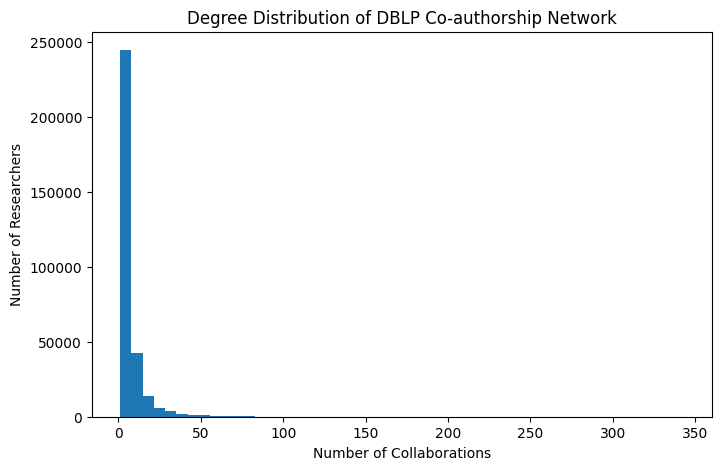

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(list(degrees.values()), bins=50)

plt.title("Degree Distribution of DBLP Co-authorship Network")
plt.xlabel("Number of Collaborations")
plt.ylabel("Number of Researchers")

plt.show()

In [ ]:
top_researchers = sorted(
    degrees.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

top_df = pd.DataFrame(
    top_researchers,
    columns=["Researcher_ID", "Number_of_Collaborations"]
)

display(top_df)

,Researcher_ID,Number_of_Collaborations
0,38868,343
1,45479,296
2,57571,290
3,6737,269
4,72210,264
5,63861,244
6,96321,230
7,13884,227
8,11457,225
9,21759,221


In [ ]:
top_df.to_csv(
    "/content/top_10_researchers.csv",
    index=False
)

In [ ]:
TARGET_NODES = 2000

start_node = max(G.degree, key=lambda x: x[1])[0]

visited = {start_node}
queue = deque([start_node])

while queue and len(visited) < TARGET_NODES:

    current = queue.popleft()

    for neighbor in G.neighbors(current):

        if neighbor not in visited:

            visited.add(neighbor)
            queue.append(neighbor)

            if len(visited) >= TARGET_NODES:
                break

H = G.subgraph(visited).copy()

print("Evaluation graph created!")
print("Researchers:", H.number_of_nodes())
print("Collaborations:", H.number_of_edges())

Evaluation graph created!
Researchers: 2000
Collaborations: 16825


In [ ]:
start_time = time.time()

louvain_communities = nx.community.louvain_communities(
    H,
    seed=42
)

louvain_time = time.time() - start_time

louvain_modularity = nx.community.modularity(
    H,
    louvain_communities
)

print("LOUVAIN RESULTS")
print("-------------------------")
print("Number of communities:", len(louvain_communities))
print("Modularity:", round(louvain_modularity, 4))
print("Execution time:", round(louvain_time, 4), "seconds")

LOUVAIN RESULTS
-------------------------
Number of communities: 16
Modularity: 0.7302
Execution time: 1.6672 seconds


In [ ]:
start_time = time.time()

greedy_communities = list(
    nx.community.greedy_modularity_communities(H)
)

greedy_time = time.time() - start_time

greedy_modularity = nx.community.modularity(
    H,
    greedy_communities
)

print("GREEDY MODULARITY RESULTS")
print("-------------------------")
print("Number of communities:", len(greedy_communities))
print("Modularity:", round(greedy_modularity, 4))
print("Execution time:", round(greedy_time, 4), "seconds")

GREEDY MODULARITY RESULTS
-------------------------
Number of communities: 22
Modularity: 0.6447
Execution time: 13.3317 seconds


In [ ]:
def get_metrics(name, communities, modularity, execution_time):

    sizes = [len(c) for c in communities]

    return {
        "Algorithm": name,
        "Number_of_Communities": len(communities),
        "Modularity": modularity,
        "Largest_Community": max(sizes),
        "Average_Community_Size": np.mean(sizes),
        "Execution_Time_Seconds": execution_time
    }


comparison = pd.DataFrame([
    get_metrics(
        "Louvain",
        louvain_communities,
        louvain_modularity,
        louvain_time
    ),

    get_metrics(
        "Greedy Modularity",
        greedy_communities,
        greedy_modularity,
        greedy_time
    )
])

display(comparison)

,Algorithm,Number_of_Communities,Modularity,Largest_Community,Average_Community_Size,Execution_Time_Seconds
0,Louvain,16,0.730227,369,125.000000,1.667159
1,Greedy Modularity,22,0.644743,752,90.909091,13.331733


In [ ]:
comparison.to_csv(
    "/content/task6_model_comparison.csv",
    index=False
)

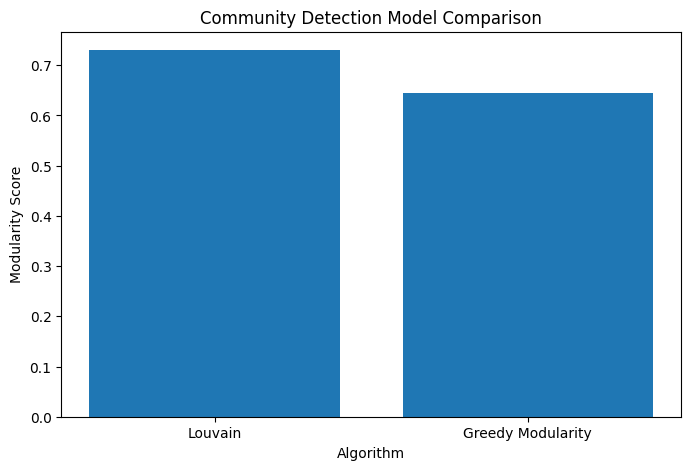

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Algorithm"],
    comparison["Modularity"]
)

plt.title("Community Detection Model Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Modularity Score")

plt.show()

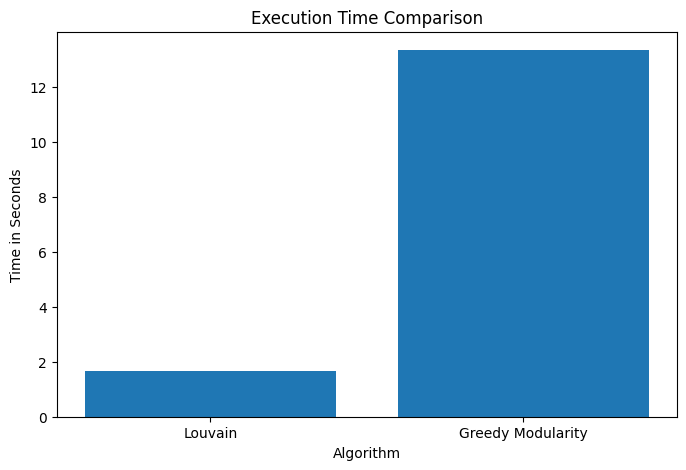

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Algorithm"],
    comparison["Execution_Time_Seconds"]
)

plt.title("Execution Time Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Time in Seconds")

plt.show()

In [ ]:
sample_degrees = dict(H.degree())

important_researchers = sorted(
    sample_degrees.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

important_df = pd.DataFrame(
    important_researchers,
    columns=["Researcher_ID", "Degree"]
)

display(important_df)

,Researcher_ID,Degree
0,38868,343
1,45479,227
2,11457,225
3,30925,162
4,1442,158
5,13076,151
6,25670,146
7,35249,145
8,148255,140
9,10516,132


In [ ]:
community_membership = {}

for community_id, community in enumerate(louvain_communities):
    for node in community:
        community_membership[node] = community_id

bridge_scores = {}

for node in H.nodes():

    neighboring_communities = {
        community_membership[n]
        for n in H.neighbors(node)
    }

    bridge_scores[node] = len(neighboring_communities)

bridge_researchers = sorted(
    bridge_scores.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

bridge_df = pd.DataFrame(
    bridge_researchers,
    columns=["Researcher_ID", "Connected_Communities"]
)

display(bridge_df)

,Researcher_ID,Connected_Communities
0,38868,12
1,1442,10
2,11457,10
3,45479,10
4,46911,10
5,35249,9
6,19114,9
7,27433,9
8,13076,9
9,57571,8


In [ ]:
important_df.to_csv(
    "/content/task6_important_researchers.csv",
    index=False
)

bridge_df.to_csv(
    "/content/task6_bridge_researchers.csv",
    index=False
)

In [ ]:
full_start = time.time()

full_communities = nx.community.louvain_communities(
    G,
    seed=42
)

full_time = time.time() - full_start

full_modularity = nx.community.modularity(
    G,
    full_communities
)

print("FULL DBLP GRAPH RESULTS")
print("-------------------------")
print("Total researchers:", G.number_of_nodes())
print("Total collaborations:", G.number_of_edges())
print("Detected communities:", len(full_communities))
print("Modularity:", round(full_modularity, 4))
print("Execution time:", round(full_time, 2), "seconds")

FULL DBLP GRAPH RESULTS
-------------------------
Total researchers: 317080
Total collaborations: 1049866
Detected communities: 202
Modularity: 0.8208
Execution time: 132.72 seconds


In [ ]:
full_summary = pd.DataFrame([{
    "Researchers": G.number_of_nodes(),
    "Collaborations": G.number_of_edges(),
    "Communities": len(full_communities),
    "Modularity": full_modularity,
    "Execution_Time_Seconds": full_time
}])

full_summary.to_csv(
    "/content/task6_full_graph_results.csv",
    index=False
)

In [ ]:
!apt-get -qq update
!apt-get -qq install openjdk-17-jdk-headless -y

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.20.1+1-1~24.04_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.20.1+1-1~24.04) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.20.1+1-1~24.04_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.20.1+1-1~24.04) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.20.1+1-1~24.04) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.021s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.021s

In [ ]:
import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PATH"] += ":" + os.environ["JAVA_HOME"] + "/bin"

print("Java environment configured!")

Java environment configured!


In [ ]:
!pip -q install pyspark==3.5.1

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.1 which is incompatible.


In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col

spark = (
    SparkSession.builder
    .appName("DBLP_Real_Time_Community_Processing")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark session started successfully!")
print("Spark Version:", spark.version)

Spark session started successfully!
Spark Version: 3.5.1


In [ ]:
from pyspark.sql.functions import col

stream_df = (
    spark.readStream
    .format("rate")
    .option("rowsPerSecond", 100)
    .option("numPartitions", 2)
    .load()
)

stream_edges = (
    stream_df
    .withColumn(
        "src",
        (col("value") % 1000).cast("long")
    )
    .withColumn(
        "dst",
        ((col("value") * 7 + 13) % 1000).cast("long")
    )
    .filter(col("src") != col("dst"))
    .select("timestamp", "src", "dst")
)

print("Streaming data source created!")
print("Is streaming:", stream_edges.isStreaming)

Streaming data source created!
Is streaming: True


In [ ]:
from datetime import datetime, timezone
import networkx as nx
import time

stream_graph = nx.Graph()

stream_metrics = []
all_stream_edges = []

def process_batch(batch_df, batch_id):

    start = time.perf_counter()

    rows = batch_df.select(
        "timestamp",
        "src",
        "dst"
    ).collect()

    if not rows:
        return

    edges = [
        (int(row["src"]), int(row["dst"]))
        for row in rows
    ]

    stream_graph.add_edges_from(edges)

    all_stream_edges.extend(edges)

    processing_time = time.perf_counter() - start

    event_count = len(edges)

    throughput = event_count / max(processing_time, 0.001)

    latest_event_time = max(
        row["timestamp"] for row in rows
    )

    processing_lag = (
        datetime.now(timezone.utc)
        - latest_event_time.replace(tzinfo=timezone.utc)
    ).total_seconds()

    processing_lag = max(processing_lag, 0)

    node_count = stream_graph.number_of_nodes()
    edge_count = stream_graph.number_of_edges()

    average_degree = (
        2 * edge_count / node_count
        if node_count > 0 else 0
    )

    stream_metrics.append({
        "Batch_ID": batch_id,
        "Incoming_Events": event_count,
        "Total_Nodes": node_count,
        "Total_Edges": edge_count,
        "Average_Degree": average_degree,
        "Processing_Time": processing_time,
        "Throughput": throughput,
        "Processing_Lag": processing_lag
    })

    print(
        f"Batch: {batch_id} | "
        f"Events: {event_count} | "
        f"Nodes: {node_count} | "
        f"Edges: {edge_count} | "
        f"Throughput: {throughput:.2f} events/sec"
    )

print("Incremental processing function created!")

Incremental processing function created!


In [ ]:
import time

stream_start = time.perf_counter()

query = (
    stream_edges.writeStream
    .foreachBatch(process_batch)
    .outputMode("append")
    .trigger(processingTime="2 seconds")
    .option(
        "checkpointLocation",
        "/content/spark_checkpoint_task7"
    )
    .start()
)

print("Streaming started successfully!")

# Run the stream for 20 seconds
time.sleep(20)

query.stop()

stream_end = time.perf_counter()

stream_wall_time = stream_end - stream_start

print("Streaming stopped successfully!")
print("Total streaming time:", round(stream_wall_time, 2), "seconds")

Streaming started successfully!
Batch: 1 | Events: 400 | Nodes: 629 | Edges: 400 | Throughput: 353.27 events/sec
Batch: 2 | Events: 200 | Nodes: 828 | Edges: 599 | Throughput: 672.00 events/sec
Batch: 3 | Events: 100 | Nodes: 901 | Edges: 698 | Throughput: 391.59 events/sec
Batch: 4 | Events: 200 | Nodes: 985 | Edges: 897 | Throughput: 1076.52 events/sec
Batch: 5 | Events: 200 | Nodes: 1000 | Edges: 996 | Throughput: 1057.62 events/sec
Batch: 6 | Events: 200 | Nodes: 1000 | Edges: 996 | Throughput: 1278.77 events/sec
Batch: 7 | Events: 200 | Nodes: 1000 | Edges: 996 | Throughput: 271.36 events/sec
Batch: 8 | Events: 200 | Nodes: 1000 | Edges: 996 | Throughput: 1298.98 events/sec
Batch: 9 | Events: 200 | Nodes: 1000 | Edges: 996 | Throughput: 1361.00 events/sec
Streaming stopped successfully!
Total streaming time: 21.37 seconds


In [ ]:
stream_metrics_df = pd.DataFrame(stream_metrics)

display(stream_metrics_df)

,Batch_ID,Incoming_Events,Total_Nodes,Total_Edges,Average_Degree,Processing_Time,Throughput,Processing_Lag
0,1,400,629,400,1.27186,1.132283,353.268625,2.095174
1,2,200,828,599,1.44686,0.297621,671.995646,0.710662
2,3,100,901,698,1.54939,0.255370,391.588681,0.651788
3,4,200,985,897,1.82132,0.185784,1076.520822,0.550381
4,5,200,1000,996,1.99200,0.189104,1057.616672,0.519086
5,6,200,1000,996,1.99200,0.156400,1278.771659,0.468892
6,7,200,1000,996,1.99200,0.737033,271.358397,1.575376
7,8,200,1000,996,1.99200,0.153967,1298.978892,0.605425
8,9,200,1000,996,1.99200,0.146951,1361.000783,0.396111


In [ ]:
stream_metrics_df.to_csv(
    "/content/task7_streaming_results.csv",
    index=False
)

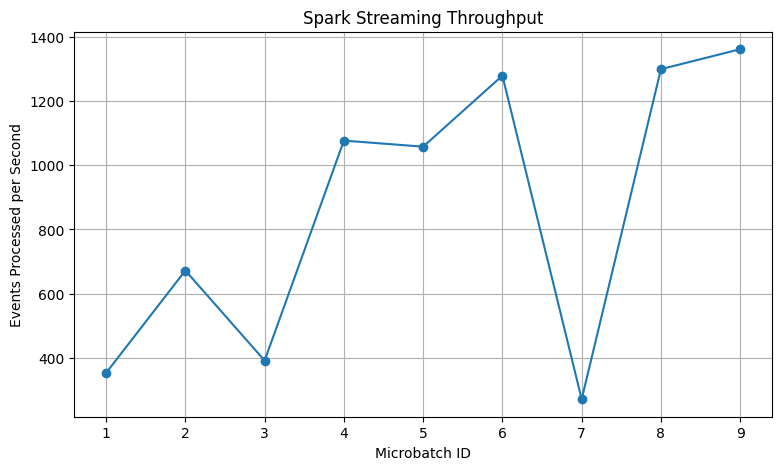

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    stream_metrics_df["Batch_ID"],
    stream_metrics_df["Throughput"],
    marker="o"
)

plt.title("Spark Streaming Throughput")
plt.xlabel("Microbatch ID")
plt.ylabel("Events Processed per Second")

plt.grid(True)
plt.show()

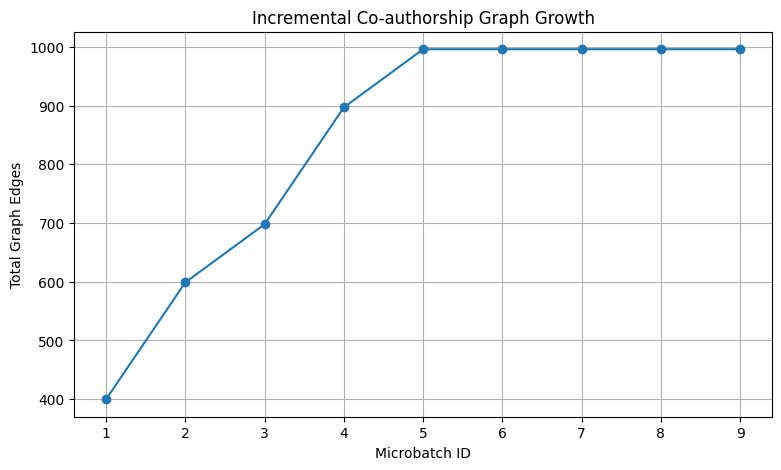

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    stream_metrics_df["Batch_ID"],
    stream_metrics_df["Total_Edges"],
    marker="o"
)

plt.title("Incremental Co-authorship Graph Growth")
plt.xlabel("Microbatch ID")
plt.ylabel("Total Graph Edges")

plt.grid(True)
plt.show()

In [ ]:
batch_graph = nx.Graph()

batch_start = time.perf_counter()

batch_graph.add_edges_from(all_stream_edges)

batch_processing_time = time.perf_counter() - batch_start

batch_comparison = pd.DataFrame([
    {
        "Processing_Mode": "Streaming",
        "Total_Events": len(all_stream_edges),
        "Final_Nodes": stream_graph.number_of_nodes(),
        "Final_Edges": stream_graph.number_of_edges(),
        "Elapsed_Time_Seconds": stream_wall_time
    },
    {
        "Processing_Mode": "Batch",
        "Total_Events": len(all_stream_edges),
        "Final_Nodes": batch_graph.number_of_nodes(),
        "Final_Edges": batch_graph.number_of_edges(),
        "Elapsed_Time_Seconds": batch_processing_time
    }
])

display(batch_comparison)

,Processing_Mode,Total_Events,Final_Nodes,Final_Edges,Elapsed_Time_Seconds
0,Streaming,1900,1000,996,21.368289
1,Batch,1900,1000,996,0.005589


In [ ]:
batch_comparison.to_csv(
    "/content/task7_batch_vs_streaming.csv",
    index=False
)

In [ ]:
from google.colab import files

output_files = [
    "/content/top_10_researchers.csv",
    "/content/task6_model_comparison.csv",
    "/content/task6_important_researchers.csv",
    "/content/task6_bridge_researchers.csv",
    "/content/task7_streaming_results.csv",
    "/content/task7_batch_vs_streaming.csv"
]

for file_path in output_files:

    if os.path.exists(file_path):
        print("Downloading:", os.path.basename(file_path))
        files.download(file_path)

Downloading: top_10_researchers.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: task6_model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (8 outputs left out)

<IPython.core.display.Javascript object>

Downloading: task7_batch_vs_streaming.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("/content/task6_full_graph_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>